# E83: Do the decomposition's masks shrink a real update on the 67M too?

*2026-11-04, `regating-lead`. A one-off for Q3 of the update notes; it does not reopen the re-gating line. Record: `reports/analyses/2026-11-04_analysis_e83-logit-shift-67m.md`. No independent check.*

**The answer.** Yes. We added two finished updates to the 67M model as an extra term the masks cannot touch, and measured how far that term moved the logits under each kind of mask. The masks shrank the effect to between a seventh and a little over half of its size with no masks. The order matches Qwen3-1.7B, which keeps about half as much. This is size only: it says nothing about whether the update's direction survives.


## What we were trying to test

We took two finished updates of the 67M model, one trained with Adam and one a rank-8 LoRA, both on lowercase tasks. Each update is applied to every matrix's input and added to that matrix's output, whatever the masks do. The decomposition's masks then act on everything else.

The bar is the size of the logit change this term causes under the masks, divided by its size with no masks. Each change is centred per position and summed over Pile validation rows 0 to 255. A bar of 1 means the masks did not touch the update's effect. A bar near 0 means they removed it. We compared three kinds of mask:

- **Random masks on a random subset of matrices.** This is how decomposition training draws them.
- **Random masks on all matrices.** A harder version of the same.
- **Fixed masks from Γ on the unchanged model, all matrices, Δ off.** This is the decomposition's own choice of subcomponents.

We expected the order fixed masks, then random masks on all matrices, then the random subset, then 1. We leaned, with low confidence, that fixed masks stay under 0.5. Qwen3-1.7B showed the same order on its first update.


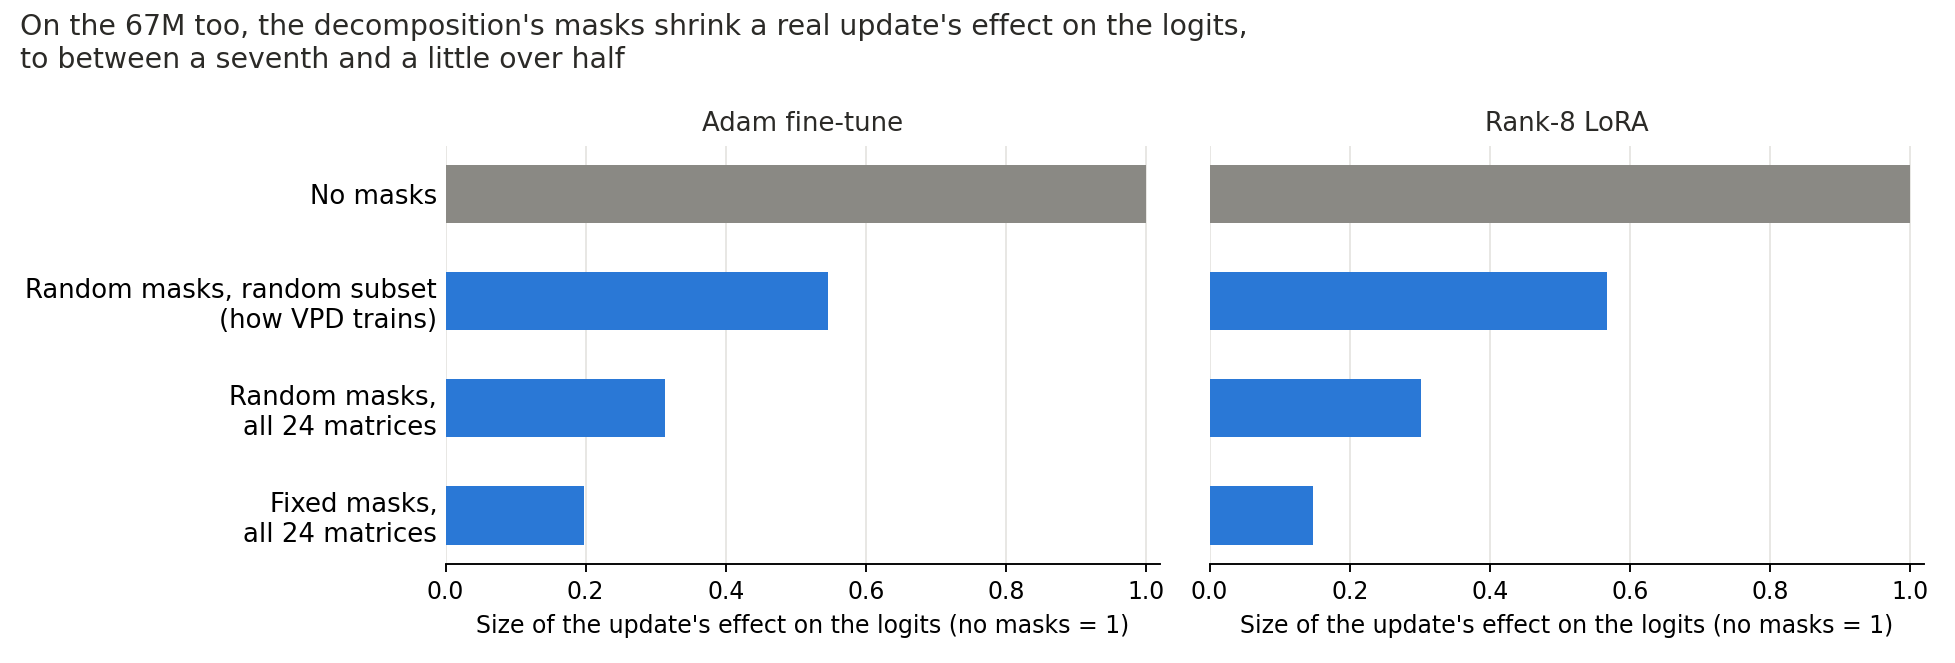

In [ ]:
from pathlib import Path
from IPython.display import Image, display

display(Image(filename=str(Path("../experiments/logit_shift_67m/figures/logit_shift.png")), width=760))


**Reading it.** Yes: the masks shrink a real update's effect on the 67M. With random masks on a random subset the effect falls to 0.55 for Adam and 0.57 for the LoRA. With random masks on all 24 matrices it falls to about 0.3, and with fixed masks from Γ to 0.20 and 0.15. The order is the one we expected, and the two updates agree. The table adds Qwen3-1.7B's first update, which keeps 0.26, 0.13 and 0.10, so the 67M keeps about twice as much. That comparison crosses models, matrix counts of 24 against 196, row lengths and updates, so it describes the gap and does not say which difference causes it.

| Masks | Adam | Rank-8 LoRA | Qwen, first update |
| --- | --- | --- | --- |
| No masks | 1 | 1 | 1 |
| Random masks, random subset, as VPD trains | 0.55 | 0.57 | 0.26 |
| Random masks, all matrices | 0.31 | 0.30 | 0.13 |
| Fixed masks from Γ on the unchanged model, all matrices, Δ off | 0.20 | 0.15 | 0.10 |


## Do the controls hold?

Yes, all four, on both updates, and the last-matrix one ran first.

- **Last matrix alone.** With every matrix masked and the change only in the last one, the update read 1.02 for Adam and 1.12 for the LoRA. A Gaussian scaled to the same clean KL read 0.79 for both. The filed band was 0.5 to 1.5, and Qwen read 0.99 and 0.95. So the shrinking is not a fault of how the term reaches the logits. Why the LoRA reads above 1 was not looked into.
- **Term against weights.** The added term and the same update written into the weights agree to under a millionth of the clean KL.
- **Masked forward.** It reads a KL of 0.3476 from the unchanged model, against 0.3482 in E71 on the same rows.
- **No matrix masked.** It reads exactly 1.

## What we learned

A real update's effect on the logits also shrinks under the decomposition's masks on the 67M, and it shrinks in the same order as on Qwen3-1.7B. For `GOALS.md` this bears on how to read faithfulness checks after an update, since the masks hide part of what the update does. It does not say whether the update's direction survives, or why the masks shrink it.

## How compelling is the evidence

The bar is size only: a change of the right size in the wrong direction would read 1. One start of masks and routes was read, with no error bars. Both updates cover the same lowercase tasks and the same 256 rows. Both filed predictions held on both updates. There was no independent check.

## Surprises

None. The LoRA's last-matrix read of 1.12 is above 1 and was not looked into.

## Departures from the literature and from the Qwen read

- **The read itself.** It is this project's, not the VPD paper's. Random masks and routing follow the library's training draw, with k uniform on 1 to 24.
- **Rows.** 256 rows of 512 tokens, against Qwen's 32 rows of 256, to match the slide.
- **Batches.** Batches of 8, not one row at a time. Each row still gets its own draws, and the route draws are three per batch.
- **Precision.** Forwards in fp32 with Γ under the authors' bf16, as on Qwen. E71's reference KL was read under bf16.

## Not run

Cosine or KL ratios, which the task excluded. Other update sizes, other rows, other seeds. Plain SGD's update, though its file exists. Any explanation of the gap to Qwen.

Provenance: Slurm job 51367, one L40, about 4 minutes, $0. Results in `experiments/logit_shift_67m/`.
